# Feature Engineering and Statistical Analysis
This notebook documents and validates the launch-time features used by the modeling pipeline.
Goals:
1. Reuse the exact training partition created in `03_preprocess_data.ipynb`.
2. Exclude post-launch outcome variables from feature analysis.
3. Generate and validate engineered launch-time features.
4. Summarize descriptive relationships between candidate features and campaign success with sample sizes and Wilson confidence intervals.
5. Record which features are included, deferred, or excluded before model tuning.
   
`X_test` is not used for statistical exploration or feature decisions in this notebook.

In [1]:
import sys
from pathlib import Path

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.features import add_base_columns, ask_features, creator_history, effort_flags, rate_plot, rate_table, reward_features, timing_features
pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# 1. Reconstruct the official training partition
Feature analysis must use the same cleaned data and project-ID split saved by preprocessing. Post-launch variables are removed before analysis because they are unavailable at campaign launch and would leak outcome information.

In [3]:
processed_dir = PROJECT_ROOT / "data" / "Processed-Data"
clean_df = pd.read_csv(processed_dir / "DSI_kickstarterscrape_dataset_cleaned.csv")
train_split = pd.read_csv(processed_dir / "train_project_ids.csv")

In [5]:
clean_by_id = clean_df.set_index("project id", drop=False)
train_rows = clean_by_id.loc[train_split["project id"]].copy().reset_index(drop=True)
y_train = train_split["target"].astype(int).reset_index(drop=True)

In [6]:
assert np.array_equal(train_rows["status"].eq("successful").astype(int).to_numpy(), y_train.to_numpy())

POST_LAUNCH = ["pledged", "funded percentage", "backers", "updates", "comments"]
train_df = train_rows.drop(columns=["status", *POST_LAUNCH], errors="ignore")
train_df["target"] = y_train.to_numpy()

In [7]:
assert train_df["project id"].tolist() == train_split["project id"].tolist()
assert not any(col in train_df.columns for col in POST_LAUNCH)

print("Training rows:", len(train_df))
print("Success rate:", f"{train_df['target'].mean():.3f}")
print("Columns:", train_df.columns.tolist())

Training rows: 29288
Success rate: 0.547
Columns: ['project id', 'name', 'url', 'category', 'subcategory', 'location', 'goal', 'funded date', 'levels', 'reward levels', 'duration', 'target']


In [8]:
info = pd.DataFrame({"dtype": train_df.dtypes.astype(str), "non_null": train_df.notna().sum(), "missing": train_df.isna().sum(), "missing_pct": (train_df.isna().mean() * 100).round(2), "unique": train_df.nunique()})
info

,dtype,non_null,missing,missing_pct,unique
project id,int64,29288,0,0.00,29288
name,object,29288,0,0.00,29253
url,object,29288,0,0.00,29288
category,object,29288,0,0.00,13
subcategory,object,29288,0,0.00,49
location,object,28401,887,3.03,3692
goal,float64,29288,0,0.00,1352
funded date,object,29288,0,0.00,26662
levels,int64,29288,0,0.00,56
reward levels,object,29247,41,0.14,18858


# 2. Generate engineered launch-time features
The reusable feature logic lives in `utils/features.py`. Category-relative goal statistics are calculated from the training partition here for validation; during model cross-validation they are learned inside the pipeline from each training fold.

In [9]:
raw_features = train_df.drop(columns="target")
base_df = add_base_columns(raw_features)
ask_df, subcat_median, cat_median = ask_features(base_df)
reward_df = reward_features(base_df)
effort_df = effort_flags(base_df)
timing_df = timing_features(base_df)

In [10]:
engineered_df = pd.concat([ask_df, reward_df, effort_df, timing_df], axis=1)
engineered_df = engineered_df.loc[:, ~engineered_df.columns.duplicated()]

In [11]:
print("Engineered feature count:", engineered_df.shape[1])
engineered_df.head()

Engineered feature count: 32


,log_goal,goal_vs_subcat,goal_vs_cat,goal_per_tier,goal_per_day,backers_needed,n_tiers,log_min_tier,log_max_tier,log_median_tier,...,title_len,title_words,title_has_subtitle,title_allcaps,title_excl,launch_month_sin,launch_month_cos,launch_dow,launch_weekend,duration
0,10.239996,2.233295,1.722602,8.160554,6.006469,6.308170,7,0.693147,6.908755,3.931826,...,47,9,1,0,0,8.660254e-01,5.000000e-01,4,0,67.96
1,8.779711,0.756621,0.773010,6.007123,5.345724,4.164591,15,0.693147,6.908755,4.615121,...,45,6,1,0,0,-2.449294e-16,1.000000e+00,1,0,30.00
2,7.003974,-1.002727,-0.897403,4.295924,3.571278,3.175333,14,1.791759,6.216606,3.828641,...,40,6,1,0,0,1.000000e+00,6.123234e-17,0,0,29.96
3,8.294300,0.692897,-0.405382,7.195687,4.683382,4.893102,2,3.218876,3.555348,3.401197,...,26,3,0,0,0,8.660254e-01,-5.000000e-01,0,0,36.00
4,7.824446,-0.182255,-0.182255,5.521861,4.133070,4.110874,9,1.791759,5.707110,3.713572,...,43,7,0,0,0,8.660254e-01,-5.000000e-01,1,0,39.10


## Feature groups
- Ask size: log goal, goal relative to category/subcategory norms, goal per reward tier, goal per day, and goal relative to the median reward tier.
- Reward structure: number of tiers, tier-price summaries, spread, entry price relative to goal, geometric tier spacing, and low-cost reward availability.
- Campaign setup/title: goal-rounding flags, common duration flags, location availability, creator URL pattern, and title-shape indicators.
- Launch timing: cyclical launch month, day of week, weekend indicator, and duration.
creator_history() is implemented as a possible future feature family but is not included in the current modeling pipeline because it uses prior campaign targets. If it is added later, it should be wrapped in a fold-safe transformer so validation rows cannot contribute outcome information.

# 3. Validate engineered features
Missing engineered values can be legitimate. For example, campaigns without usable reward tiers do not have minimum, maximum, or median reward values. The modeling pipeline handles numeric missingness inside each training fold.

In [13]:
feature_validation = pd.DataFrame({"dtype": engineered_df.dtypes.astype(str), "missing": engineered_df.isna().sum(), "missing_pct": (engineered_df.isna().mean() * 100).round(2), "unique": engineered_df.nunique()})
feature_validation.sort_values(["missing_pct", "unique"], ascending=[False, False])

,dtype,missing,missing_pct,unique
geo_step,float64,736,2.51,2456
backers_needed,float64,41,0.14,6501
entry_vs_goal,float64,41,0.14,3030
tier_spread,float64,41,0.14,1430
log_max_tier,float64,41,0.14,513
log_median_tier,float64,41,0.14,491
share_under_50,float64,41,0.14,219
log_min_tier,float64,41,0.14,66
n_cheap,float64,41,0.14,23
goal_per_day,float64,0,0.00,14807


In [14]:
numeric_features = engineered_df.select_dtypes(include=np.number)
infinite_counts = pd.Series(np.isinf(numeric_features.to_numpy()).sum(axis=0), index=numeric_features.columns, name="infinite_values")

In [15]:
assert infinite_counts.sum() == 0
assert engineered_df["n_tiers"].dropna().ge(0).all()
assert engineered_df["n_cheap"].dropna().ge(0).all()
assert engineered_df["share_under_50"].dropna().between(0, 1).all()
assert engineered_df["launch_month_sin"].dropna().between(-1, 1).all()
assert engineered_df["launch_month_cos"].dropna().between(-1, 1).all()
assert engineered_df["launch_dow"].dropna().between(0, 6).all()
assert set(engineered_df["launch_weekend"].dropna().unique()).issubset({0, 1})

print("Feature validation passed.")

Feature validation passed.


In [16]:
engineered_df.describe().T

,count,mean,std,min,25%,50%,75%,max
log_goal,29288.0,8.231075,1.292070,0.009950,7.378384,8.294300e+00,9.047939,15.068274
goal_vs_subcat,29288.0,-0.034037,1.221655,-8.581857,-0.772831,0.000000e+00,0.693036,7.061573
goal_vs_cat,29288.0,-0.024062,1.254319,-8.111928,-0.791604,0.000000e+00,0.693047,6.550881
goal_per_tier,29288.0,6.139411,1.232654,-2.564949,5.367977,6.119498e+00,6.907855,13.017004
goal_per_day,29288.0,4.605595,1.255752,-3.722314,3.815246,4.576977e+00,5.384069,11.478525
backers_needed,29247.0,3.999616,1.154710,-6.734195,3.270669,3.922972e+00,4.656588,11.831383
n_tiers,29288.0,7.947863,4.165407,0.000000,5.000000,7.000000e+00,10.000000,75.000000
log_min_tier,29247.0,1.667512,0.919902,0.693147,0.693147,1.791759e+00,2.397895,9.210440
log_max_tier,29247.0,6.559336,1.631768,0.693147,5.525453,6.908755e+00,7.824446,9.210440
log_median_tier,29247.0,4.232574,0.890016,0.693147,3.650658,4.330733e+00,4.615121,9.210440


# 4. Goal distribution and success rate
Campaign goals are strongly right-skewed, so the modeling features include log_goal rather than relying only on the raw dollar scale. The grouped analysis below is descriptive: it summarizes observed success rates and uncertainty but does not imply that lowering a goal alone causes success.

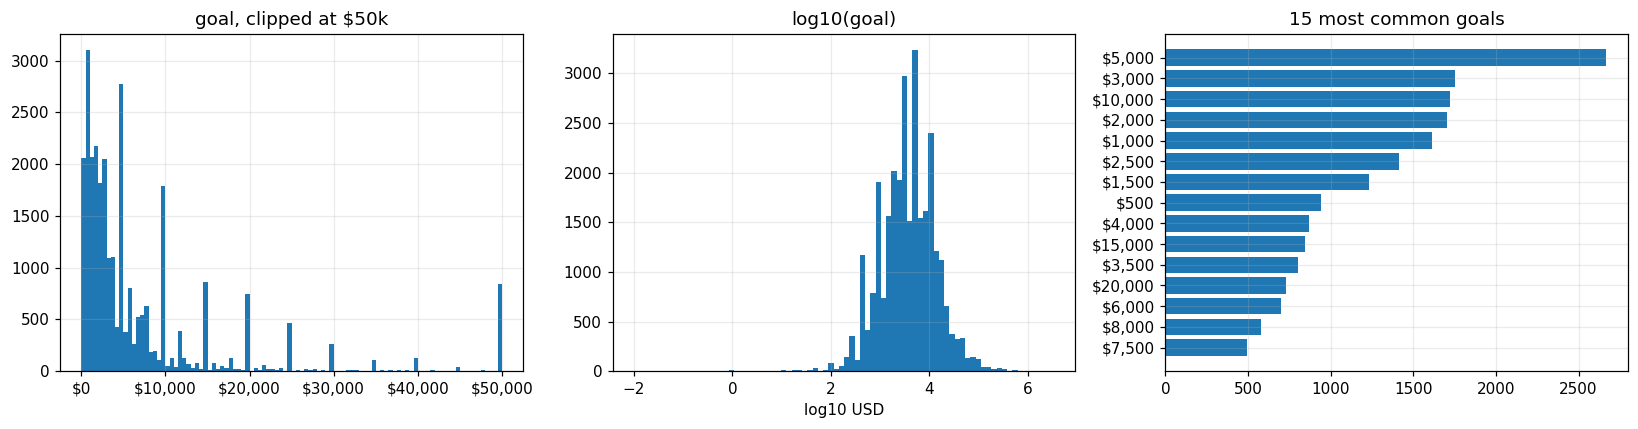

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(train_df["goal"].clip(upper=50_000), bins=100)
axes[0].set_title("goal, clipped at $50k")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1].hist(np.log10(train_df["goal"]), bins=80)
axes[1].set_title("log10(goal)")
axes[1].set_xlabel("log10 USD")
top = train_df["goal"].value_counts().head(15)
axes[2].barh([f"${int(v):,}" for v in top.index][::-1], top.values[::-1])
axes[2].set_title("15 most common goals")
plt.tight_layout()

,n,rate,ci_lo,ci_hi,vs_base
goal,,,,,
<$500,2060,0.717,0.697,0.736,0.169
$500–1k,3100,0.673,0.656,0.689,0.125
$1–2k,4248,0.659,0.644,0.673,0.111
$2–3k,3868,0.621,0.605,0.636,0.073
$3–5k,5388,0.549,0.535,0.562,0.001
$5–7.5k,2494,0.525,0.506,0.545,-0.022
$7.5–10k,2909,0.465,0.447,0.483,-0.082
$10–15k,1803,0.416,0.393,0.439,-0.131
$15–25k,1783,0.322,0.301,0.345,-0.225


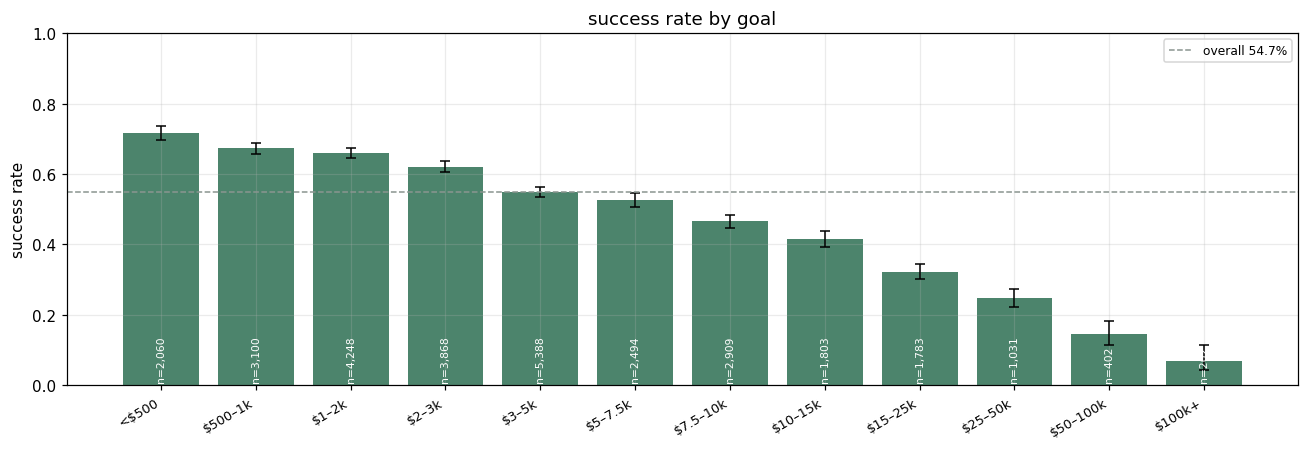

In [19]:
bins = [0, 500, 1000, 2000, 3000, 5000, 7500, 10000, 15000, 25000, 50000, 100000, 1e9]
labels = ["<$500", "$500–1k", "$1–2k", "$2–3k", "$3–5k", "$5–7.5k", "$7.5–10k", "$10–15k", "$15–25k", "$25–50k", "$50–100k", "$100k+"]
g_goal = rate_table(train_df, pd.cut(train_df["goal"], bins, labels=labels))

fig, ax = plt.subplots(figsize=(12, 4.2))
rate_plot(ax, g_goal, "success rate by goal", rotate=30)
plt.tight_layout()
g_goal[["n", "rate", "ci_lo", "ci_hi", "vs_base"]].round(3)

# 5. Campaign duration
Duration is examined separately because it may capture campaign-planning choices and may interact with campaign size. Only groups with at least 50 campaigns are retained by rate_table().

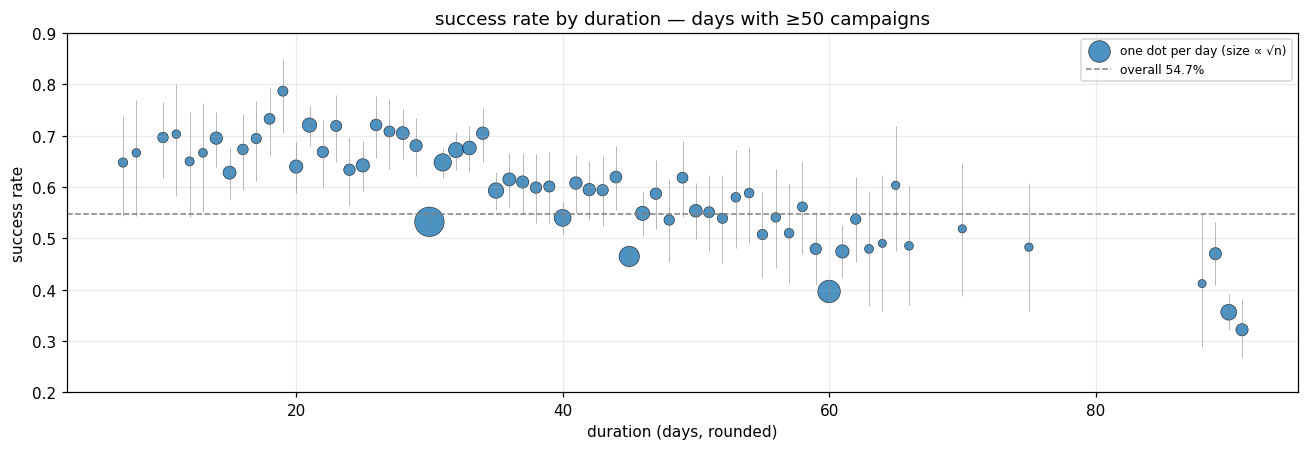

In [21]:
by_day = rate_table(train_df, train_df["duration"].round().astype(int))

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.scatter(by_day.index, by_day["rate"], s=np.sqrt(by_day["n"]) * 4, alpha=0.8, edgecolor="k", lw=0.4, label="one dot per day (size ∝ √n)")
ax.errorbar(by_day.index, by_day["rate"], yerr=[by_day["rate"] - by_day["ci_lo"], by_day["ci_hi"] - by_day["rate"]], fmt="none", ecolor="grey", lw=0.6, alpha=0.6)
ax.axhline(by_day.attrs["base"], color="grey", ls="--", lw=1, label=f"overall {by_day.attrs['base']:.1%}")
ax.set_xlabel("duration (days, rounded)")
ax.set_ylabel("success rate")
ax.set_ylim(0.2, 0.9)
ax.set_title("success rate by duration — days with ≥50 campaigns")
ax.legend(fontsize=8)
plt.tight_layout()

# 6. Category and subcategory
Category composition is uneven, so success-rate differences should be read together with group sizes. Category and subcategory are retained as categorical model inputs and encoded inside the training pipeline.

,n,share,cumulative_share,n_subcategories,median_goal
category,,,,,
Film & Video,8846,0.302,0.302,6,5000.0
Music,6978,0.238,0.540,10,3000.0
Publishing,2862,0.098,0.638,8,3500.0
Art,2617,0.089,0.727,9,2700.0
Theater,1618,0.055,0.783,1,2650.0
Design,1068,0.036,0.819,4,6000.0
Games,1050,0.036,0.855,3,5000.0
Photography,977,0.033,0.888,1,3000.0
Food,913,0.031,0.919,1,7500.0


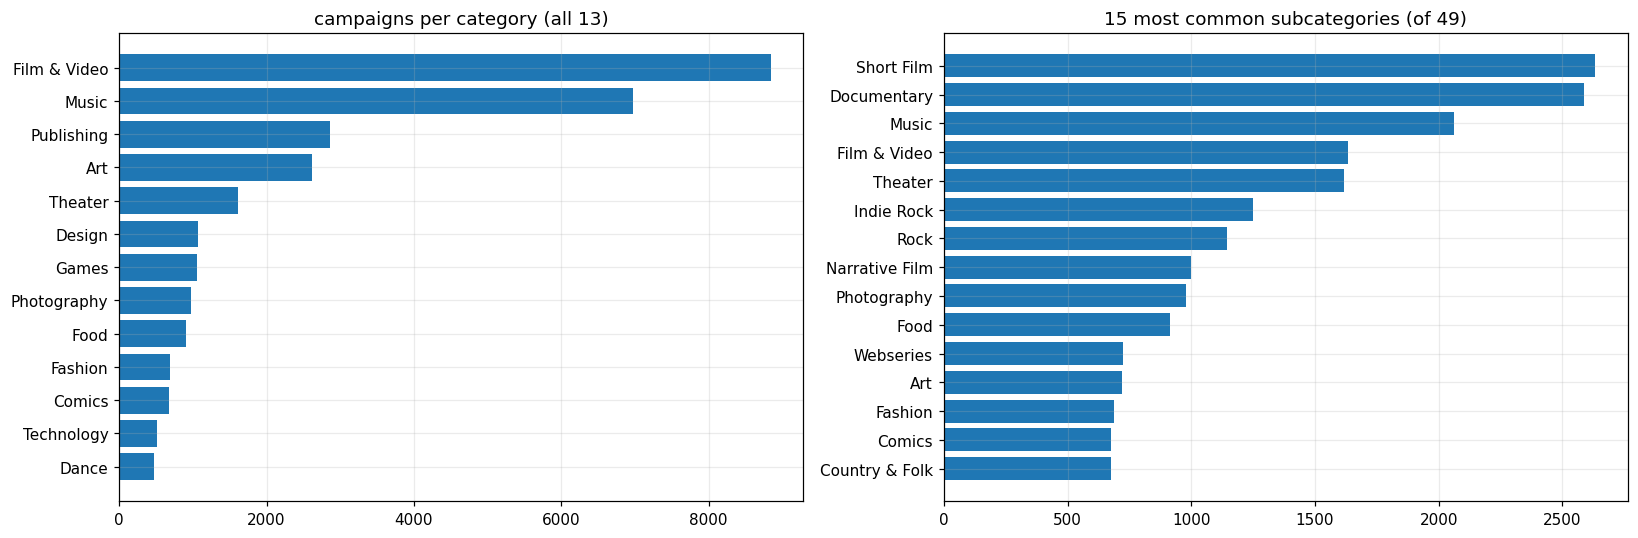

In [23]:
cat_n = train_df["category"].value_counts()
sub_n = train_df["subcategory"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(cat_n.index[::-1], cat_n.values[::-1])
axes[0].set_title(f"campaigns per category (all {len(cat_n)})")
topk = sub_n.head(15)
axes[1].barh(topk.index[::-1], topk.values[::-1])
axes[1].set_title(f"15 most common subcategories (of {len(sub_n)})")
plt.tight_layout()

summary = pd.DataFrame({"n": cat_n, "share": cat_n / len(train_df)})
summary["cumulative_share"] = summary["share"].cumsum()
summary["n_subcategories"] = train_df.groupby("category")["subcategory"].nunique()
summary["median_goal"] = train_df.groupby("category")["goal"].median()
summary.round(3)

,n,rate,ci_lo,ci_hi,vs_base,median_goal
category,,,,,,
Dance,475,0.762,0.722,0.798,0.215,2500.0
Theater,1618,0.705,0.682,0.726,0.157,2650.0
Music,6978,0.675,0.663,0.685,0.127,3000.0
Art,2617,0.575,0.556,0.594,0.027,2700.0
Comics,677,0.548,0.510,0.585,0.001,3000.0
Film & Video,8846,0.511,0.500,0.521,-0.037,5000.0
Food,913,0.505,0.473,0.537,-0.042,7500.0
Photography,977,0.466,0.435,0.497,-0.082,3000.0
Design,1068,0.464,0.435,0.494,-0.083,6000.0


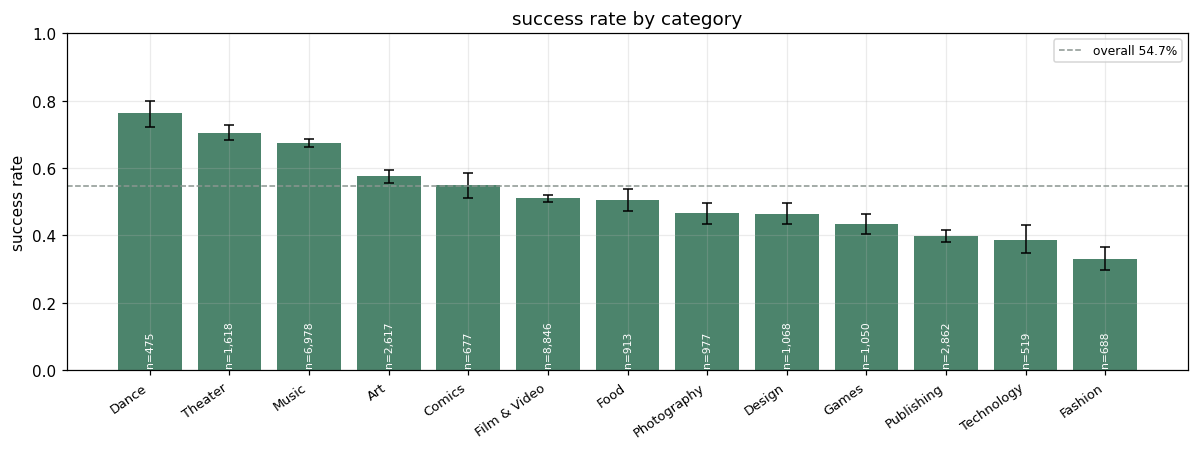

In [24]:
g_cat = rate_table(train_df, "category").sort_values("rate", ascending=False)
g_cat["median_goal"] = train_df.groupby("category")["goal"].median()

fig, ax = plt.subplots(figsize=(11, 4.2))
rate_plot(ax, g_cat, "success rate by category", rotate=35)
plt.tight_layout()
g_cat[["n", "rate", "ci_lo", "ci_hi", "vs_base", "median_goal"]].round(3)

,n,rate,ci_lo,ci_hi,category,median_goal
subcategory,,,,,,
Dance,475,0.762,0.722,0.798,Dance,2500.0
Country & Folk,677,0.752,0.718,0.783,Music,3000.0
Indie Rock,1249,0.744,0.719,0.767,Music,2500.0
Classical Music,305,0.734,0.682,0.781,Music,3000.0
Jazz,303,0.713,0.660,0.761,Music,4000.0
Theater,1618,0.705,0.682,0.726,Theater,2650.0
Rock,1146,0.681,0.653,0.707,Music,2500.0
Pop,503,0.662,0.620,0.702,Music,3500.0
Public Art,345,0.661,0.609,0.709,Art,3000.0


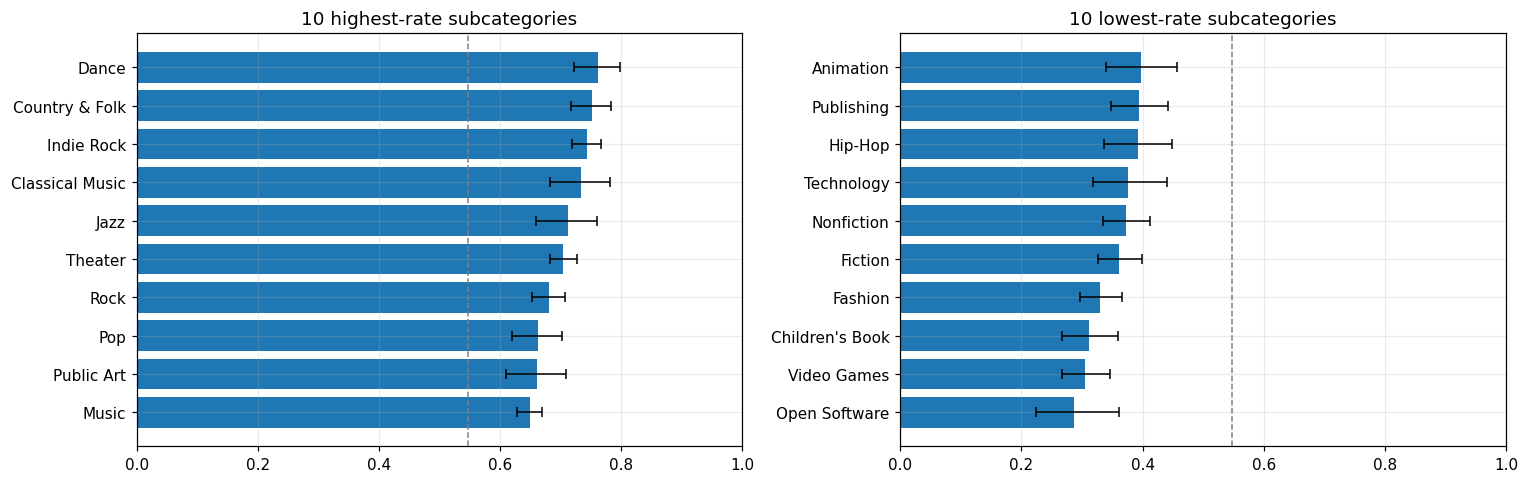

In [25]:
g_sub = rate_table(train_df, "subcategory", min_n=150)
g_sub["category"] = train_df.groupby("subcategory")["category"].agg(lambda s: s.mode()[0])
g_sub["median_goal"] = train_df.groupby("subcategory")["goal"].median()
top_sub, bottom_sub = g_sub.nlargest(10, "rate"), g_sub.nsmallest(10, "rate")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, group, title in [(axes[0], top_sub.iloc[::-1], "10 highest-rate subcategories"), (axes[1], bottom_sub, "10 lowest-rate subcategories")]:
    ax.barh(group.index, group["rate"])
    ax.errorbar(group["rate"], range(len(group)), xerr=[group["rate"] - group["ci_lo"], group["ci_hi"] - group["rate"]], fmt="none", ecolor="k", capsize=3, lw=1)
    ax.axvline(train_df["target"].mean(), color="grey", ls="--", lw=1)
    ax.set_xlim(0, 1)
    ax.set_title(title)
plt.tight_layout()

pd.concat([top_sub, bottom_sub])[["n", "rate", "ci_lo", "ci_hi", "category", "median_goal"]].round(3)

,n,rate,ci_lo,ci_hi,category,median_goal
subcategory,,,,,,
Dance,475,0.762,0.722,0.798,Dance,2500.0
Country & Folk,677,0.752,0.718,0.783,Music,3000.0
Indie Rock,1249,0.744,0.719,0.767,Music,2500.0
Classical Music,305,0.734,0.682,0.781,Music,3000.0
Jazz,303,0.713,0.660,0.761,Music,4000.0
Theater,1618,0.705,0.682,0.726,Theater,2650.0
Rock,1146,0.681,0.653,0.707,Music,2500.0
Pop,503,0.662,0.620,0.702,Music,3500.0
Public Art,345,0.661,0.609,0.709,Art,3000.0


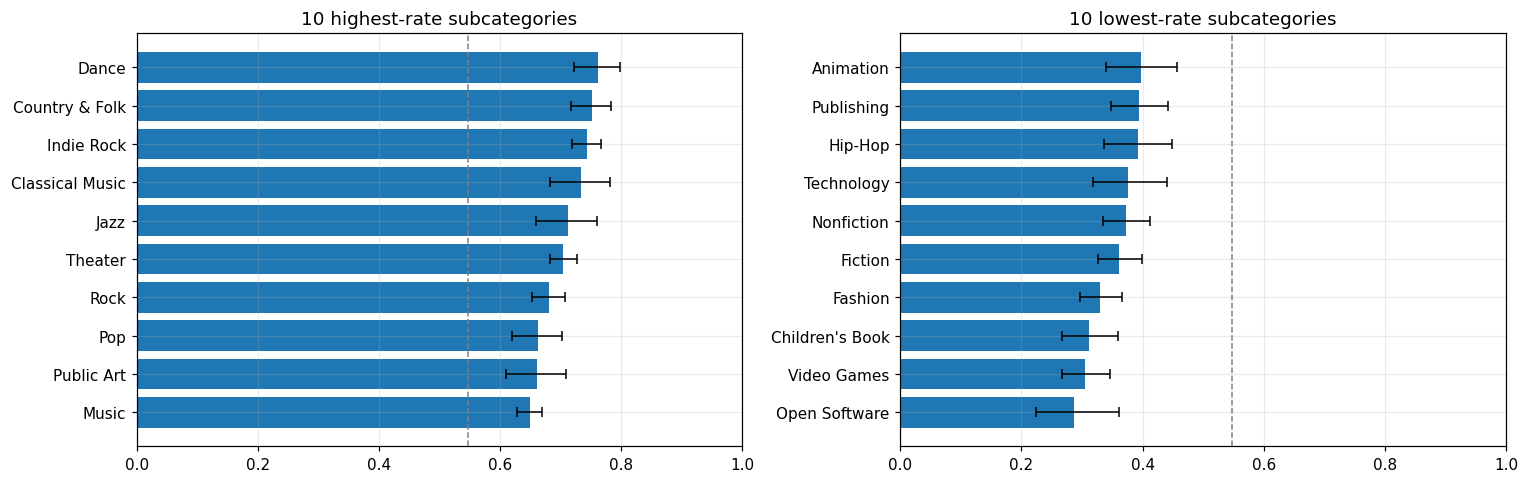

In [26]:
g_sub = rate_table(train_df, "subcategory", min_n=150)
g_sub["category"] = train_df.groupby("subcategory")["category"].agg(lambda s: s.mode()[0])
g_sub["median_goal"] = train_df.groupby("subcategory")["goal"].median()
top_sub, bottom_sub = g_sub.nlargest(10, "rate"), g_sub.nsmallest(10, "rate")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, group, title in [(axes[0], top_sub.iloc[::-1], "10 highest-rate subcategories"), (axes[1], bottom_sub, "10 lowest-rate subcategories")]:
    ax.barh(group.index, group["rate"])
    ax.errorbar(group["rate"], range(len(group)), xerr=[group["rate"] - group["ci_lo"], group["ci_hi"] - group["rate"]], fmt="none", ecolor="k", capsize=3, lw=1)
    ax.axvline(train_df["target"].mean(), color="grey", ls="--", lw=1)
    ax.set_xlim(0, 1)
    ax.set_title(title)
plt.tight_layout()

pd.concat([top_sub, bottom_sub])[["n", "rate", "ci_lo", "ci_hi", "category", "median_goal"]].round(3)

# 7. Reward-tier structure
Reward tiers are parsed into model features such as tier count, entry level, spread, and geo_step, the approximate multiplicative step from the lowest to highest tier. The relationship below is descriptive and can be confounded by category, goal size, and campaign type.

,n,rate,ci_lo,ci_hi,vs_base
geo_step,,,,,
"(0.999, 1.699]",3583,0.681,0.665,0.696,0.127
"(1.699, 1.919]",3677,0.631,0.616,0.647,0.078
"(1.919, 2.115]",3838,0.603,0.588,0.619,0.050
"(2.115, 2.187]",3533,0.595,0.579,0.611,0.041
"(2.187, 2.43]",3585,0.539,0.523,0.555,-0.014
"(2.43, 2.683]",3224,0.508,0.491,0.525,-0.046
"(2.683, 3.162]",3556,0.465,0.449,0.481,-0.089
"(3.162, 1000.0]",3556,0.395,0.379,0.411,-0.159


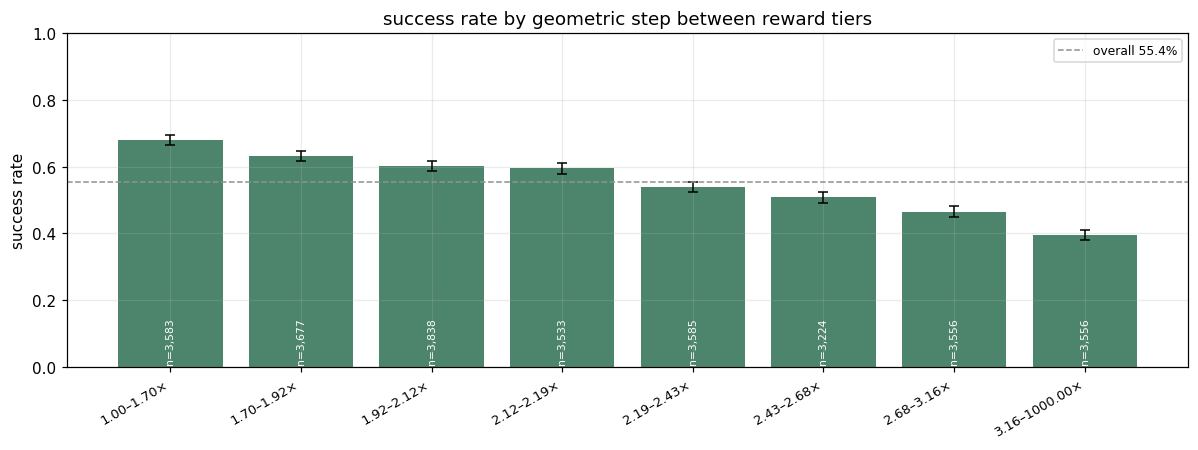

In [28]:
reward_analysis = train_df[["target"]].copy()
reward_analysis["geo_step"] = engineered_df["geo_step"]
reward_analysis = reward_analysis.dropna(subset=["geo_step"])

ts = rate_table(reward_analysis, pd.qcut(reward_analysis["geo_step"], 8, duplicates="drop"))
fig, ax = plt.subplots(figsize=(11, 4.2))
rate_plot(ax, ts, "success rate by geometric step between reward tiers", labels=[f"{iv.left:.2f}–{iv.right:.2f}×" for iv in ts.index], rotate=30)
plt.tight_layout()
ts[["n", "rate", "ci_lo", "ci_hi", "vs_base"]].round(3)

# 8. Geography and location availability
State is extracted from the trailing two-letter location abbreviation after normalizing it to uppercase. Missing location is preserved and represented separately through has_location.

                  n   rate  ci_lo  ci_hi  vs_base
has_location                                     
blank           887  0.484  0.451  0.517   -0.064
given         28401  0.549  0.544  0.555    0.002


,n,rate,ci_lo,ci_hi,vs_base
state,,,,,
FL,962,0.362,0.332,0.393,-0.186
NV,230,0.370,0.310,0.434,-0.178
NJ,385,0.423,0.375,0.473,-0.124
GA,697,0.425,0.388,0.462,-0.123
AZ,382,0.437,0.388,0.487,-0.110
IL,1214,0.598,0.570,0.625,0.051
OR,802,0.599,0.564,0.632,0.051
LA,303,0.627,0.571,0.680,0.080
MA,852,0.643,0.610,0.675,0.096


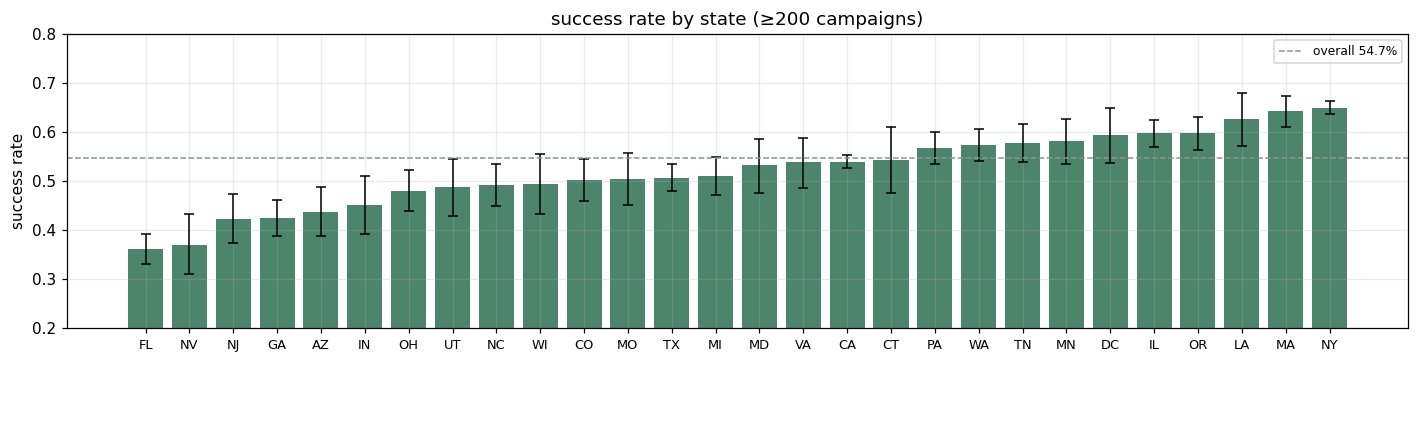

In [30]:
geo_analysis = train_df[["target", "location"]].copy()
geo_analysis["state"] = base_df["state"]
geo_analysis["has_location"] = train_df["location"].notna().astype(int)

print(rate_table(geo_analysis, "has_location").rename(index={0: "blank", 1: "given"})[["n", "rate", "ci_lo", "ci_hi", "vs_base"]].round(3))

g_st = rate_table(geo_analysis, "state", min_n=200).sort_values("rate")
fig, ax = plt.subplots(figsize=(13, 4.2))
rate_plot(ax, g_st, "success rate by state (≥200 campaigns)")
ax.set_ylim(0.2, 0.8)
plt.tight_layout()
pd.concat([g_st.head(5), g_st.tail(5)])[["n", "rate", "ci_lo", "ci_hi", "vs_base"]].round(3)

# 9. Interactions: category × goal and goal × duration
Univariate success rates do not isolate causal effects. These cross-tabulations check whether the observed relationships vary across campaign context. Cells with fewer than 30 campaigns are left unannotated to avoid over-emphasizing very small groups.

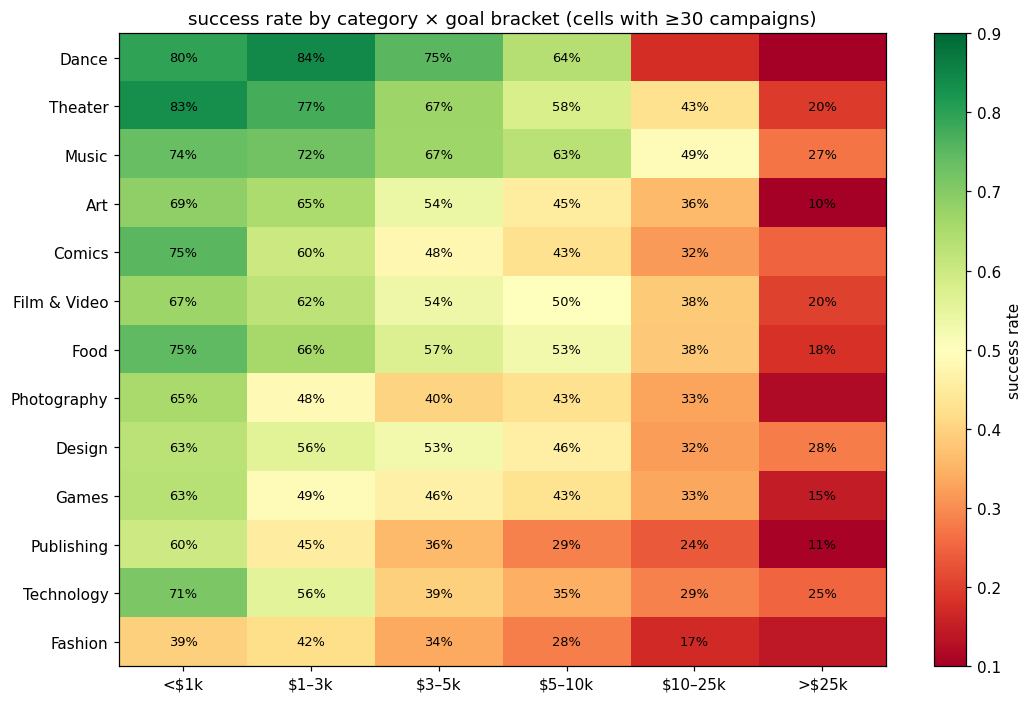

In [31]:
goal_bracket = pd.cut(train_df["goal"], [0, 1000, 3000, 5000, 10000, 25000, 1e9], labels=["<$1k", "$1–3k", "$3–5k", "$5–10k", "$10–25k", ">$25k"])
ct = pd.crosstab(train_df["category"], goal_bracket, values=train_df["target"], aggfunc="mean")
cn = pd.crosstab(train_df["category"], goal_bracket)
ct = ct.reindex(g_cat.index)
cn = cn.reindex(g_cat.index)

fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(ct.values, cmap="RdYlGn", vmin=0.1, vmax=0.9, aspect="auto")
ax.set_xticks(range(ct.shape[1]))
ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0]))
ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        if cn.iloc[i, j] >= 30:
            ax.text(j, i, f"{ct.iloc[i, j]:.0%}", ha="center", va="center", fontsize=8.5)
plt.colorbar(im, ax=ax, label="success rate")
ax.grid(False)
ax.set_title("success rate by category × goal bracket (cells with ≥30 campaigns)")
plt.tight_layout()

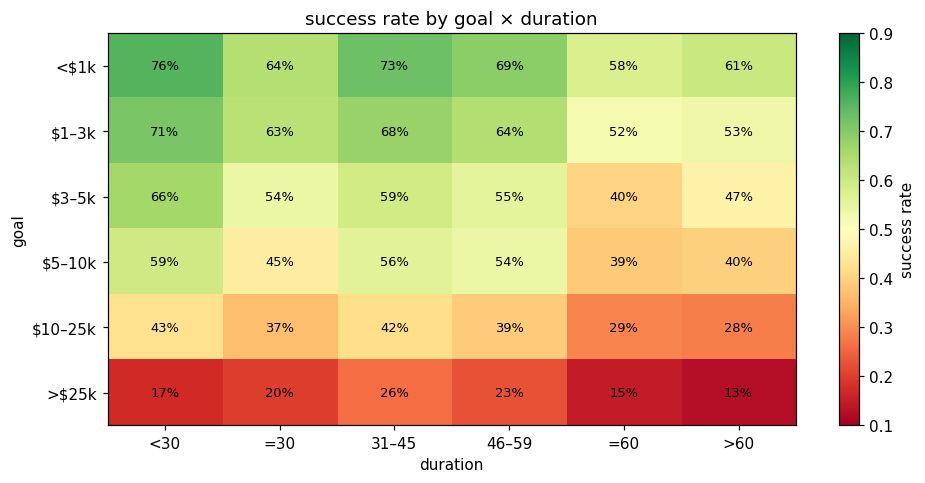

In [32]:
duration_bracket = pd.cut(train_df["duration"], [0, 29.5, 30.5, 45, 59.5, 60.5, 100], labels=["<30", "=30", "31–45", "46–59", "=60", ">60"])
ct2 = pd.crosstab(goal_bracket, duration_bracket, values=train_df["target"], aggfunc="mean")
cn2 = pd.crosstab(goal_bracket, duration_bracket)

fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(ct2.values, cmap="RdYlGn", vmin=0.1, vmax=0.9, aspect="auto")
ax.set_xticks(range(ct2.shape[1]))
ax.set_xticklabels(ct2.columns)
ax.set_xlabel("duration")
ax.set_yticks(range(ct2.shape[0]))
ax.set_yticklabels(ct2.index)
ax.set_ylabel("goal")
for i in range(ct2.shape[0]):
    for j in range(ct2.shape[1]):
        if cn2.iloc[i, j] >= 30:
            ax.text(j, i, f"{ct2.iloc[i, j]:.0%}", ha="center", va="center", fontsize=8.5)
plt.colorbar(im, ax=ax, label="success rate")
ax.grid(False)
ax.set_title("success rate by goal × duration")
plt.tight_layout()

# 10. Leakage and feature-status review
Included in the current model pipeline
- campaign ask and relative-goal features;
- reward-tier structure;
- launch-time campaign setup/title indicators;
- category, subcategory, and state;
- launch timing and duration.
  
### Excluded
- pledged, funded percentage, backers, updates, and comments because they are post-launch outcome variables;
- the previous renamed feature because comparing the current title with a URL slug can encode a change that occurred after launch.

### Deferred
- creator-history features. They require target information from earlier campaigns and therefore need a dedicated fold-safe implementation before they can be used in model validation.
  
`funded date` is currently used with `duration` to reconstruct launch timing. Before the final model is locked, the source-field semantics should be confirmed so this date is known to represent an allowable campaign timing field rather than an outcome event.

# Conclusions
The training-set analysis supports campaign goal, category/subcategory, duration, reward structure, geography, title/setup characteristics, and launch timing as candidate predictors of Kickstarter success.
Several descriptive patterns are strong enough to motivate engineered representations. Goal is highly skewed and success rates vary across goal ranges, supporting logarithmic and relative-goal features. Category and subcategory show substantial variation in observed success rates, supporting categorical encoding. Reward-tier spacing and other reward-ladder characteristics also vary with success, motivating dedicated reward features. Duration appears weaker on its own and is better interpreted together with campaign goal and other context.
Wilson confidence intervals are reported for grouped success rates so observed differences are interpreted together with sample size and uncertainty. These comparisons are descriptive associations, not causal estimates.
The feature-engineering implementation is now validated against the official training partition. Post-launch outcome variables are excluded, the potentially post-launch renamed feature is removed, and learned category-relative quantities remain inside the modeling pipeline so they are fit only on training folds during cross-validation.
The next step is model tuning and evaluation using the unchanged official split.